I0000 00:00:1794288329.184200  202819 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794288329.648196  202819 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794288331.185639  202819 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


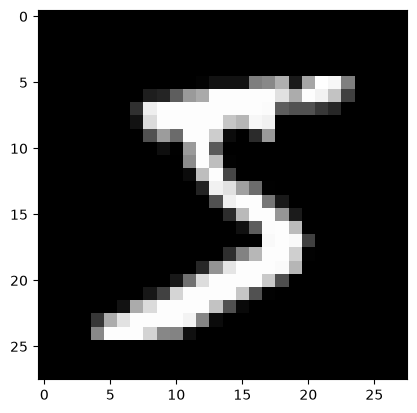

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
# Normalizacion: los pixeles pasan de 0-255 a 0-1
x_train = x_train.reshape(x_train.shape[0], 28*28).astype('float32') / 255.0
x_test  = x_test.reshape(x_test.shape[0], 28*28).astype('float32') / 255.0

plt.imshow(x_train[0].reshape(28,28), cmap='gray')
plt.show()

In [2]:
In = tf.keras.layers.Input(shape=(784,))
Cp1 = tf.keras.layers.Dense(64, activation='relu')(In)
Cp2 = tf.keras.layers.Dense(16, activation='relu')(Cp1) #El relu quita los valores que sean menores a 0
Out = tf.keras.layers.Dense(10, activation='softmax')(Cp2) #El softmax de vuelve un vector con probabilidades de pertencer a una clase [ 0, 0, 0, 0, 0, 0, 0, 0.7, 0, 0, 0.3, 0] esto nos puedes mostrar la seguridad del model, aunque esta seguridad no asegura que el modelo sea confiable
Model = tf.keras.Model(inputs=In, outputs=Out)

In [3]:
Model.summary() # Similar a un PCA dinamico-en la parte de abajo en el total

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,450 (200.98 KB)

 Trainable params: 51,450 (200.98 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
Model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
Model.fit(x_train, y_train, epochs=30, batch_size=32)

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 937us/step - accuracy: 0.9101 - loss: 0.3127
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9562 - loss: 0.1479
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 886us/step - accuracy: 0.9671 - loss: 0.1106
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 919us/step - accuracy: 0.9737 - loss: 0.0871
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 912us/step - accuracy: 0.9770 - loss: 0.0731
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 909us/step - accuracy: 0.9805 - loss: 0.0621
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 928us/step - accuracy: 0.9829 - loss: 0.0544
Epoch 8/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 931us/step - accuracy: 0.9855 - loss: 0.0462
Epoch 9/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 889us/step - accuracy: 0.9869 - loss: 0.0410
Epoch 10/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 914us/step - accuracy: 0.9887 - loss: 0.0359
Epoch 11/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 932us/step - accuracy: 0.9901 - loss: 0.0312
Epoch 12/3

In [5]:
import io
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
from PIL import Image

# ------------------ INTERFAZ ------------------
title = widgets.HTML("""
<div style="font-family:'Segoe UI',Arial,sans-serif; padding:18px 22px;
            background:linear-gradient(135deg,#667eea 0%,#764ba2 100%);
            border-radius:14px; color:white; text-align:center;
            box-shadow:0 4px 14px rgba(0,0,0,.25);">
  <h2 style="margin:0; font-size:22px;"> Clasificador de Dígitos MNIST</h2>
  <p style="margin:6px 0 0; font-size:13px; opacity:.9;">
     Sube una imagen (PNG/JPG) con un dígito escrito a mano y el modelo lo clasificará en tiempo real.
  </p>
</div>
""")

uploader = widgets.FileUpload(
    accept='.png,.jpg,.jpeg',
    multiple=False,
    description='📤 Subir Imagen',
    button_style='success',
    icon='upload',
    layout=widgets.Layout(width='210px')
)

output = widgets.Output()


# ---------------- PREPROCESADO ----------------
import cv2
from scipy.ndimage import center_of_mass, shift

def preprocess_image(img):
    """Preprocesado robusto tipo MNIST: binarización, recorte y centrado por centro de masa."""
    img_gray = img.convert('L')
    img_np = np.array(img_gray)

    # 1. Invertir si el fondo es claro (detectar promedio de esquinas)
    if np.mean([img_np[0,0], img_np[0,-1], img_np[-1,0], img_np[-1,-1]]) > 127:
        img_np = 255 - img_np

    # 2. Binarización (Umbralización de Otsu) para eliminar sombras y ruido
    # Esto deja el fondo en 0 (negro puro) y el número en 255 (blanco puro)
    _, img_np = cv2.threshold(img_np, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 3. Quedarse SOLO con la mancha más grande (el dígito).
    #    Sin esto, cualquier sombra o borde de la foto entra al recuadro y el
    #    número queda encogido y deformado (un 0 termina pareciendo un 4).
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(img_np, 8)
    if n > 1:
        mayor = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        img_np = (etiquetas == mayor).astype(np.uint8) * 255

    # 4. Encontrar el recuadro del número
    coords = cv2.findNonZero(img_np)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        img_np = img_np[y:y+h, x:x+w]

    # 5. Redimensionar a 20x20 manteniendo proporción (como indica el paper de MNIST)
    h, w = img_np.shape
    if h > w:
        new_h = 20
        new_w = int(w * (20 / h))
    else:
        new_w = 20
        new_h = int(h * (20 / w))

    img_resized = cv2.resize(img_np, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # 6. Crear lienzo negro de 28x28 y pegar el número
    canvas = np.zeros((28, 28), dtype=np.uint8)
    start_y = (28 - new_h) // 2
    start_x = (28 - new_w) // 2
    canvas[start_y:start_y+new_h, start_x:start_x+new_w] = img_resized

    # 7. Centrar por "Centro de Masa" (Crucial para MLPs)
    cy, cx = center_of_mass(canvas)
    shift_y, shift_x = np.round(14 - cy), np.round(14 - cx)
    canvas = shift(canvas, shift=(shift_y, shift_x), cval=0)

    return canvas


# ---------------- CALLBACK ----------------
def on_upload(change):
    with output:
        clear_output(wait=True)
        if not uploader.value:
            return

        # Compatibilidad ipywidgets v7 / v8
        if isinstance(uploader.value, dict):
            uploaded_file = next(iter(uploader.value.values()))
        else:
            uploaded_file = uploader.value[0]

        content = uploaded_file['content']
        img = Image.open(io.BytesIO(content))

        # Preprocesar
        img_28 = preprocess_image(img)

        # Predicción: MISMO escalado que el entrenamiento (0-1)
        x = img_28.reshape(1, 784).astype('float32') / 255.0
        probs = Model.predict(x, verbose=0)[0]
        pred = int(np.argmax(probs))
        conf = float(probs[pred] * 100)

        # ---- Tarjetas de resultado ----
        display(HTML(f"""
        <div style="font-family:'Segoe UI',Arial,sans-serif; display:flex;
                    gap:12px; margin:14px 0; flex-wrap:wrap;">
          <div style="flex:1; min-width:150px; padding:16px; border-radius:12px;
                      background:linear-gradient(135deg,#43e97b,#38f9d7);
                      color:#083b2f; text-align:center;
                      box-shadow:0 4px 10px rgba(0,0,0,.15);">
            <div style="font-size:12px; letter-spacing:1px; text-transform:uppercase;">Predicción</div>
            <div style="font-size:46px; font-weight:800; line-height:1;">{pred}</div>
          </div>
          <div style="flex:1; min-width:150px; padding:16px; border-radius:12px;
                      background:linear-gradient(135deg,#4facfe,#00f2fe);
                      color:#062a4a; text-align:center;
                      box-shadow:0 4px 10px rgba(0,0,0,.15);">
            <div style="font-size:12px; letter-spacing:1px; text-transform:uppercase;">Confianza</div>
            <div style="font-size:46px; font-weight:800; line-height:1;">{conf:.1f}%</div>
          </div>
        </div>
        """))

        # ---- Paneles lado a lado ----
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
        fig.patch.set_facecolor('#f8f9fb')

        # Panel izquierdo: imagen procesada
        ax1.imshow(img_28, cmap='gray', vmin=0, vmax=255)
        ax1.set_title('Imagen procesada (28×28)', fontsize=12, fontweight='bold', pad=10)
        ax1.axis('off')

        # Panel derecho: barras horizontales de probabilidad
        y_pos = np.arange(10)
        colors = ['#d0d7e2'] * 10
        colors[pred] = '#4CAF50'
        bars = ax2.barh(y_pos, probs, color=colors, edgecolor='white', height=0.72)

        ax2.set_yticks(y_pos)
        ax2.set_yticklabels([str(i) for i in range(10)], fontweight='bold')
        ax2.invert_yaxis()
        ax2.set_xlim(0, 1.08)
        ax2.set_xlabel('Probabilidad', fontsize=10)
        ax2.set_title('Distribución de confianza', fontsize=12, fontweight='bold', pad=10)
        ax2.grid(axis='x', alpha=0.25, linestyle='--')
        ax2.set_axisbelow(True)
        for s in ['top', 'right']:
            ax2.spines[s].set_visible(False)

        for bar in bars:
            w = bar.get_width()
            if w > 0.01:
                ax2.text(w + 0.015, bar.get_y() + bar.get_height() / 2,
                         f'{w * 100:.1f}%', va='center', ha='left',
                         fontsize=8.5, fontweight='bold', color='#333')

        plt.tight_layout()
        plt.show()


uploader.observe(on_upload, names='value')

# Mostrar la UI
display(widgets.VBox([title, uploader, output],
                     layout=widgets.Layout(margin='10px 0 0 0')))